# Pipeline 1: Razonamiento, Búsqueda y Resultados
**Challenge 1 (Individual) – Machine Learning – UPCH**
**Caso Tipo C: Sueño en los Recién Nacidos (0–3 meses)**

Pipeline: **Problema → Espacio de Estados → Exploración → Búsqueda → Resultado**

Este notebook representa el razonamiento que seguiría una IA para explorar soluciones: partimos de un bebé con sueño fragmentado y buscamos la secuencia de acciones de menor costo que lleva a un patrón de sueño más consolidado.

In [1]:
import heapq
import itertools
from collections import deque

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

## 1. Problema
**¿Qué secuencia de acciones, y a qué costo, lleva de un patrón de sueño desorganizado a uno más consolidado en un recién nacido?**

Datos del caso (infografía): 162 bebés y 100 padres, más de 25 000 horas de actigrafía, ciclos de sueño de ~40 min que aumentan ~10 min entre los 3 y 12 meses, y recién nacidos que duermen ~16 h/día de forma fragmentada.

In [2]:
problema = {
    "caso": "Sueño en recién nacidos (0-3 meses)",
    "pregunta": "Secuencia de acciones de menor costo hacia un sueño más consolidado",
    "evidencia": {
        "bebes": 162, "padres": 100, "horas_actigrafia": "> 25 000",
        "ciclo_sueno_min": 40, "aumento_ciclo_3_a_12_meses_min": 10,
        "horas_sueno_dia_recien_nacido": 16,
    },
}
for k, v in problema.items():
    print(f"{k}: {v}")

caso: Sueño en recién nacidos (0-3 meses)
pregunta: Secuencia de acciones de menor costo hacia un sueño más consolidado
evidencia: {'bebes': 162, 'padres': 100, 'horas_actigrafia': '> 25 000', 'ciclo_sueno_min': 40, 'aumento_ciclo_3_a_12_meses_min': 10, 'horas_sueno_dia_recien_nacido': 16}


## 2. Espacio de estados
- **Estado:** `(info, rutina, ambiente, señales)`, cada variable es 0 (no) o 1 (sí). Total: 16 estados.
- **Estado inicial:** `(0,0,0,0)`.
- **Meta:** `rutina = 1`, `ambiente = 1` y `señales = 1` (por las restricciones, el único estado meta alcanzable es `1111`).
- **Operadores:** con precondiciones, efectos y costo.
- **Restricciones:** rutina y señales (por cuenta propia) requieren `info = 1`; los operadores solo cambian 0 → 1.

In [3]:
VARS = ("info", "rutina", "ambiente", "señales")
IDX = {v: i for i, v in enumerate(VARS)}

INICIO = (0, 0, 0, 0)

# nombre: (costo, precondiciones {var: valor}, efectos [vars que pasan a 1])
OPERADORES = {
    "O1 Buscar información y acompañamiento": (1, {"info": 0}, ["info"]),
    "O2 Establecer rutina de sueño":          (2, {"info": 1, "rutina": 0}, ["rutina"]),
    "O3 Adecuar ambiente de sueño":           (1, {"ambiente": 0}, ["ambiente"]),
    "O4 Aprender señales de cansancio":       (1, {"info": 1, "señales": 0}, ["señales"]),
    "O5 Consulta con profesional de salud":   (3, {"info": 0}, ["info", "señales"]),
}


def es_meta(s):
    return s[IDX["rutina"]] == 1 and s[IDX["ambiente"]] == 1 and s[IDX["señales"]] == 1


def sucesores(s):
    # Devuelve (nombre_operador, costo, nuevo_estado) aplicando restricciones
    res = []
    for nombre, (costo, pre, efectos) in OPERADORES.items():
        if all(s[IDX[v]] == val for v, val in pre.items()):
            nuevo = list(s)
            for v in efectos:
                nuevo[IDX[v]] = 1
            res.append((nombre, costo, tuple(nuevo)))
    return res


def heuristica(s):
    # Admisible y consistente: variables meta faltantes (+1 si falta info y se necesita)
    faltan = sum(1 for v in ("rutina", "ambiente", "señales") if s[IDX[v]] == 0)
    necesita_info = 1 if (s[IDX["info"]] == 0 and (s[IDX["rutina"]] == 0 or s[IDX["señales"]] == 0)) else 0
    return faltan + necesita_info


print("Estados totales:", 2 ** len(VARS))
print("Sucesores del estado inicial:")
for nombre, costo, s2 in sucesores(INICIO):
    print(f"  {nombre} (costo {costo}) -> {s2}")

Estados totales: 16
Sucesores del estado inicial:
  O1 Buscar información y acompañamiento (costo 1) -> (1, 0, 0, 0)
  O3 Adecuar ambiente de sueño (costo 1) -> (0, 0, 1, 0)
  O5 Consulta con profesional de salud (costo 3) -> (1, 0, 0, 1)


## 3. Exploración
Exploramos con BFS **todos los estados alcanzables** desde el estado inicial, para saber qué tan grande es realmente el espacio y generar su representación visual.

In [4]:
def explorar(inicio):
    visitados = {inicio}
    cola = deque([inicio])
    aristas = []
    while cola:
        s = cola.popleft()
        for nombre, costo, s2 in sucesores(s):
            aristas.append((s, s2, nombre, costo))
            if s2 not in visitados:
                visitados.add(s2)
                cola.append(s2)
    return visitados, aristas


alcanzables, aristas = explorar(INICIO)
print("Estados alcanzables:", len(alcanzables), "de", 2 ** len(VARS))
print("Transiciones:", len(aristas))
print("Estados meta:", sorted(s for s in alcanzables if es_meta(s)))

Estados alcanzables: 10 de 16
Transiciones: 17
Estados meta: [(1, 1, 1, 1)]


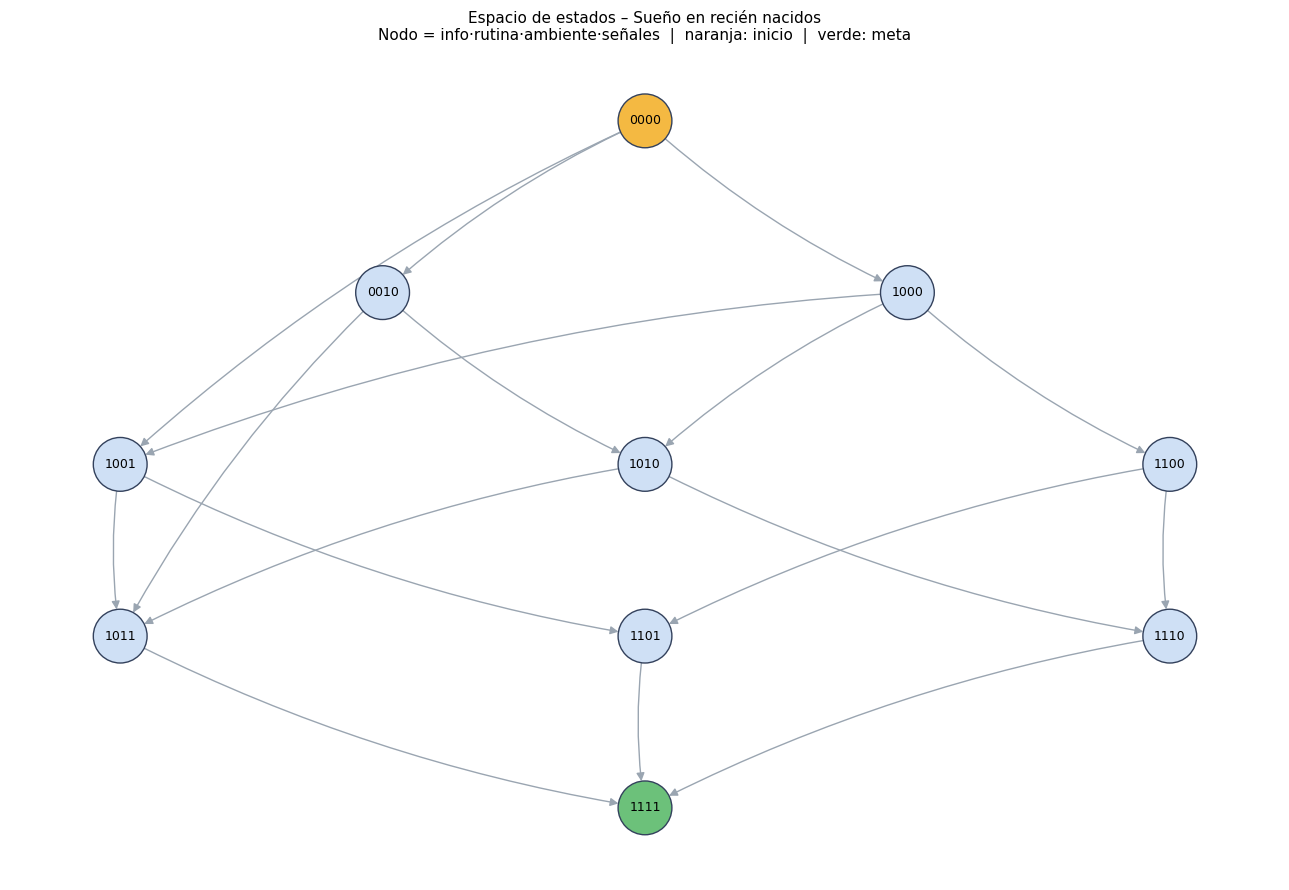

In [5]:
def etiqueta(s):
    return "".join(str(x) for x in s)


def posiciones(estados):
    capas = {}
    for s in estados:
        capas.setdefault(sum(s), []).append(s)
    pos = {}
    for k, lista in capas.items():
        lista.sort()
        n = len(lista)
        for i, s in enumerate(lista):
            pos[s] = ((i - (n - 1) / 2) * 1.6, -k * 2.2)
    return pos


def dibujar(estados, aristas, camino=None, archivo=None, titulo=""):
    G = nx.DiGraph()
    G.add_nodes_from(estados)
    for s, s2, nombre, costo in aristas:
        G.add_edge(s, s2)
    pos = posiciones(estados)
    colores = []
    for s in G.nodes:
        if s == INICIO:
            colores.append("#f4b942")
        elif es_meta(s):
            colores.append("#6cc17a")
        else:
            colores.append("#cfe0f5")
    fig, ax = plt.subplots(figsize=(13, 9))
    nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowsize=12, edge_color="#9aa5b1",
                           connectionstyle="arc3,rad=0.08", node_size=1500, width=1)
    if camino:
        pares = list(zip(camino[:-1], camino[1:]))
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=pares, arrows=True, arrowsize=18,
                               edge_color="#d1495b", width=3, node_size=1500,
                               connectionstyle="arc3,rad=0.08")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colores, node_size=1500, edgecolors="#33415c")
    nx.draw_networkx_labels(G, pos, labels={s: etiqueta(s) for s in G.nodes}, ax=ax, font_size=9)
    ax.set_title(titulo + "\nNodo = info·rutina·ambiente·señales  |  naranja: inicio  |  verde: meta"
                 + ("  |  rojo: plan" if camino else ""), fontsize=11)
    ax.axis("off")
    plt.tight_layout()
    if archivo:
        plt.savefig(archivo, dpi=150, format="jpeg")
    plt.show()


dibujar(alcanzables, aristas, archivo="espacio_de_estados.jpeg",
        titulo="Espacio de estados – Sueño en recién nacidos")

## 4. Búsqueda
Comparamos tres estrategias:

| Estrategia | Qué optimiza |
|---|---|
| **BFS** | Menor número de pasos (ignora costos) |
| **Costo uniforme (Dijkstra)** | Menor costo acumulado `g(n)` |
| **A\*** | Menor `f(n) = g(n) + h(n)` usando la heurística |

In [6]:
def reconstruir(padres, s):
    camino = []
    while s is not None:
        camino.append(s)
        s = padres[s][0]
    return camino[::-1]


def bfs(inicio):
    cola = deque([inicio])
    padres = {inicio: (None, None, 0)}
    expandidos = 0
    while cola:
        s = cola.popleft()
        expandidos += 1
        if es_meta(s):
            return reconstruir(padres, s), padres, expandidos
        for nombre, costo, s2 in sucesores(s):
            if s2 not in padres:
                padres[s2] = (s, nombre, padres[s][2] + costo)
                cola.append(s2)
    return None, padres, expandidos


def buscar_por_costo(inicio, usar_h):
    contador = itertools.count()
    frontera = [(heuristica(inicio) if usar_h else 0, next(contador), 0, inicio)]
    padres = {inicio: (None, None, 0)}
    cerrados = set()
    expandidos = 0
    while frontera:
        f, _, g, s = heapq.heappop(frontera)
        if s in cerrados:
            continue
        cerrados.add(s)
        expandidos += 1
        if es_meta(s):
            return reconstruir(padres, s), padres, expandidos
        for nombre, costo, s2 in sucesores(s):
            g2 = g + costo
            if s2 not in padres or g2 < padres[s2][2]:
                padres[s2] = (s, nombre, g2)
                h = heuristica(s2) if usar_h else 0
                heapq.heappush(frontera, (g2 + h, next(contador), g2, s2))
    return None, padres, expandidos


def costo_camino(camino, padres):
    return padres[camino[-1]][2]


def operadores_camino(camino, padres):
    return [padres[s][1] for s in camino[1:]]


resultados = {}
for nombre, funcion in {
    "BFS": lambda: bfs(INICIO),
    "Costo uniforme (Dijkstra)": lambda: buscar_por_costo(INICIO, usar_h=False),
    "A* con heurística": lambda: buscar_por_costo(INICIO, usar_h=True),
}.items():
    camino, padres, expandidos = funcion()
    resultados[nombre] = dict(camino=camino, padres=padres, expandidos=expandidos,
                              pasos=len(camino) - 1, costo=costo_camino(camino, padres))

tabla = pd.DataFrame({k: {"Pasos": v["pasos"], "Costo total": v["costo"],
                          "Nodos expandidos": v["expandidos"]} for k, v in resultados.items()}).T
tabla

,Pasos,Costo total,Nodos expandidos
BFS,3,6,10
Costo uniforme (Dijkstra),4,5,10
A* con heurística,4,5,10


## 5. Resultado
Plan encontrado por cada estrategia y comparación.

In [7]:
for nombre, r in resultados.items():
    print(f"=== {nombre} ===")
    print("Costo total:", r["costo"], "| Pasos:", r["pasos"], "| Nodos expandidos:", r["expandidos"])
    for i, op in enumerate(operadores_camino(r["camino"], r["padres"]), 1):
        print(f"  {i}. {op}")
    print("  Estados:", " -> ".join(etiqueta(s) for s in r["camino"]))
    print()

=== BFS ===
Costo total: 6 | Pasos: 3 | Nodos expandidos: 10
  1. O3 Adecuar ambiente de sueño
  2. O5 Consulta con profesional de salud
  3. O2 Establecer rutina de sueño
  Estados: 0000 -> 0010 -> 1011 -> 1111

=== Costo uniforme (Dijkstra) ===
Costo total: 5 | Pasos: 4 | Nodos expandidos: 10
  1. O1 Buscar información y acompañamiento
  2. O3 Adecuar ambiente de sueño
  3. O4 Aprender señales de cansancio
  4. O2 Establecer rutina de sueño
  Estados: 0000 -> 1000 -> 1010 -> 1011 -> 1111

=== A* con heurística ===
Costo total: 5 | Pasos: 4 | Nodos expandidos: 10
  1. O1 Buscar información y acompañamiento
  2. O3 Adecuar ambiente de sueño
  3. O4 Aprender señales de cansancio
  4. O2 Establecer rutina de sueño
  Estados: 0000 -> 1000 -> 1010 -> 1011 -> 1111



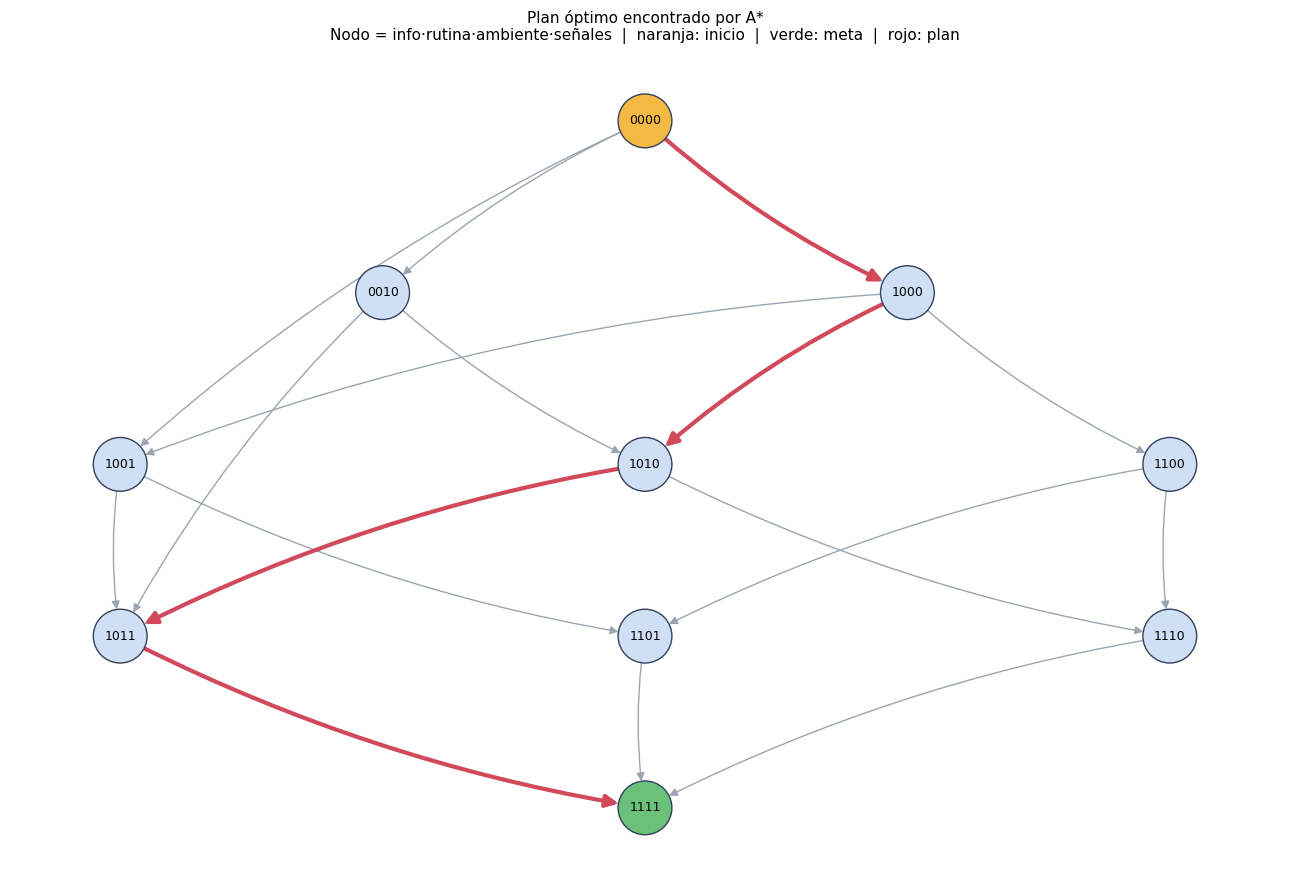

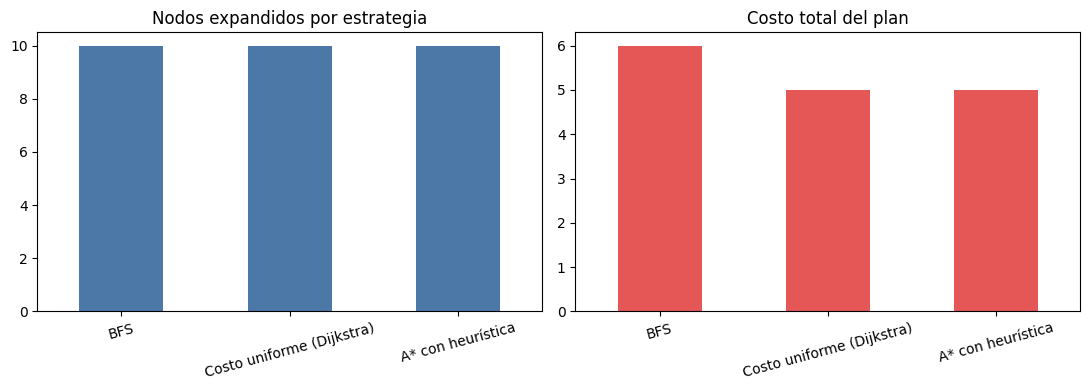

In [8]:
mejor = resultados["A* con heurística"]
dibujar(alcanzables, aristas, camino=mejor["camino"], archivo="resultado_busqueda.jpeg",
        titulo="Plan óptimo encontrado por A*")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tabla["Nodos expandidos"].plot.bar(ax=ax[0], color="#4c78a8", rot=15)
ax[0].set_title("Nodos expandidos por estrategia")
tabla["Costo total"].plot.bar(ax=ax[1], color="#e45756", rot=15)
ax[1].set_title("Costo total del plan")
plt.tight_layout()
plt.show()

## Conclusiones
1. El problema se representó como un espacio de 16 estados posibles, de los cuales **10 son alcanzables** desde el inicio (por la restricción de que rutina y señales requieren información previa, solo existe 1 estado meta: `1111`), con 5 operadores, precondiciones y costos.
2. **BFS** encuentra el plan con menos pasos (3), pero **no** el de menor costo (6).
3. **Costo uniforme** y **A\*** encuentran el plan de costo mínimo (5), con 4 pasos. Esto muestra que menos pasos no implica menor costo.
4. En este espacio tan pequeño las tres estrategias expanden los mismos 10 nodos; la ventaja de una heurística como la de A\* se nota en espacios mucho más grandes.
5. Los costos son supuestos didácticos: la infografía indica que **no se reporta** la efectividad comparativa de cada intervención. El modelo es orientativo y no reemplaza la evaluación de un pediatra.